# Detecting Lane Lines with the Hough Transform

This notebook puts the lane detection steps together into one pipeline on a photo from a highway:
1. Find the **vanishing point** of the lane lines and build the region of interest from it.
2. Keep only the edges inside the region of interest.
3. Find line **segments** with the probabilistic Hough transform, `cv2.HoughLinesP`.
4. **Average** the segments on each side into one line per lane, and extend each line to the edges of the region of interest.
5. Draw the lanes on the photo.
6. Save all results to `output/`.

The vanishing point replaces the fixed polygon of the course project. The region then adapts to the camera position in each image, instead of having to be redrawn by hand. The method is explained in [Region of Interest Selection](../region_of_interest_selection/region_of_interest_selection.ipynb).

## 1. Imports

- `cv2` (OpenCV): image I/O, edges, Hough transform, polygons and drawing
- `matplotlib`: displaying images
- `numpy`: fitting lines and array operations
- `pathlib`: file paths that work on any OS

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 80  # keeps the saved notebook small

## 2. Configuration

- `INPUT_PATH`: the highway photo.
- `SEARCH_TOP_FRACTION`, `SEARCH_BOTTOM_FRACTION`: the rows of the image, as fractions of its height, where lane segments are searched for to find the vanishing point. The bottom limit stops above the car's bonnet, which otherwise produces false lines.
- `CANNY_THRESHOLDS`, `BLUR_KSIZE`: edge detection settings.
- `HOUGH_SEARCH`: the probabilistic Hough settings for finding the vanishing point.
- `MIN_SLOPE`: segments flatter than this are not lane markings.
- `ROI_BOTTOM_FRACTION`: the bottom of the region of interest, for the same reason as the search area.
- `TOP_MARGIN`: the region of interest stops this many pixels below the vanishing point.
- `HOUGH_LANE`: the probabilistic Hough settings for the lane segments inside the region of interest. The minimum length is 60 pixels, below the 100 pixels of the course project. The region is smaller than the course's fixed polygon, and with 100 pixels only one segment remained on the left lane. With 60 pixels, each side is fitted from four segments.
- All results are saved to `OUTPUT_DIR`.

In [2]:
INPUT_PATH = Path("new_test_image_3.jpg")
OUTPUT_DIR = Path("output")

BLUR_KSIZE = 5
CANNY_THRESHOLDS = (50, 150)

SEARCH_TOP_FRACTION = 0.55
SEARCH_BOTTOM_FRACTION = 0.8
HOUGH_SEARCH = dict(threshold=40, min_length=40, max_gap=150)
MIN_SLOPE = 0.4

ROI_BOTTOM_FRACTION = 0.8
TOP_MARGIN = 15

HOUGH_LANE = dict(rho=2, theta=np.pi / 180, threshold=40, min_length=60, max_gap=50)

## 3. Helper functions

- `load_image` wraps `cv2.imread`, which returns `None` on failure instead of raising an error.
- `show_images` shows several images side by side. Colour images are converted from BGR to RGB before display.
- `roi_mask` and `draw_polygon` create and show a polygon region.
- `find_segments` finds line segments in an edge image and sorts them into the left and right lanes by slope.
- `fit_x_of_y` fits one line $x = k\,y + c$ through the endpoints of a set of segments.
- `vanishing_point` intersects the two fitted lines.
- `roi_from_vanishing_point` builds the trapezoid from the vanishing point down to the bottom of the search area.
- `extend_line` returns the fitted line between two rows, so that a lane can be drawn across the region of interest.
- `save_image` writes an image and checks the result.

In [3]:
def load_image(path: Path) -> np.ndarray:
    """Load a colour image with OpenCV (BGR order) and raise a clear error if it fails."""
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path.resolve()}")
    return image


def show_images(images: dict[str, np.ndarray], cols: int | None = None, size: float = 5.0) -> None:
    """Show several images side by side. Colour images are converted from BGR to RGB for matplotlib."""
    cols = cols or len(images)
    rows = -(-len(images) // cols)  # ceiling division
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 0.75),
                             squeeze=False, layout="constrained")
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (title, img) in zip(axes.ravel(), images.items()):
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
    plt.show()


def roi_mask(shape: tuple[int, ...], polygon: np.ndarray) -> np.ndarray:
    """Single-channel mask: 255 inside the polygon, 0 outside."""
    mask = np.zeros(shape[:2], dtype=np.uint8)
    return cv2.fillPoly(mask, polygon, 255)


def draw_polygon(img: np.ndarray, polygon: np.ndarray) -> np.ndarray:
    """Return a copy of the image with the polygon outline drawn in red."""
    out = img.copy()
    cv2.polylines(out, polygon, isClosed=True, color=(0, 0, 255), thickness=3)
    return out


def find_segments(edges: np.ndarray) -> tuple[list, list]:
    """Probabilistic Hough segments split into (left, right) lane candidates by slope."""
    segments = cv2.HoughLinesP(edges, 1, np.pi / 180, **{
        "threshold": HOUGH_SEARCH["threshold"],
        "minLineLength": HOUGH_SEARCH["min_length"],
        "maxLineGap": HOUGH_SEARCH["max_gap"],
    })
    left, right = [], []
    if segments is None:
        return left, right
    for x1, y1, x2, y2 in segments.reshape(-1, 4):
        if x2 == x1:
            continue  # exactly vertical: no slope to compare
        slope = (y2 - y1) / (x2 - x1)
        if abs(slope) < MIN_SLOPE:
            continue
        (left if slope < 0 else right).append((int(x1), int(y1), int(x2), int(y2)))
    return left, right


def fit_x_of_y(segments: list) -> tuple[float, float]:
    """Least-squares line x = k * y + c through all the endpoints of the segments."""
    pts = np.array([(x, y) for x1, y1, x2, y2 in segments for x, y in ((x1, y1), (x2, y2))], dtype=float)
    A = np.column_stack([pts[:, 1], np.ones(len(pts))])
    k, c = np.linalg.lstsq(A, pts[:, 0], rcond=None)[0]
    return k, c


def vanishing_point(left_fit: tuple[float, float], right_fit: tuple[float, float], height: int):
    """Intersection of the two fitted lines, or None if they are parallel or meet outside the image."""
    kl, cl = left_fit
    kr, cr = right_fit
    if abs(kl - kr) < 1e-6:
        return None
    y = (cr - cl) / (kl - kr)
    x = kl * y + cl
    if not (0 < y < height):
        return None
    return x, y


def roi_from_vanishing_point(left_fit, right_fit, vp_y: float, bottom: int, width: int) -> np.ndarray:
    """Trapezoid from the bottom row up to just below the vanishing point, clipped to the image."""
    top = int(vp_y) + TOP_MARGIN
    x_left = lambda y: left_fit[0] * y + left_fit[1]
    x_right = lambda y: right_fit[0] * y + right_fit[1]
    corners = [(x_left(bottom), bottom), (x_left(top), top), (x_right(top), top), (x_right(bottom), bottom)]
    clipped = [(int(np.clip(x, 0, width - 1)), int(np.clip(y, 0, bottom))) for x, y in corners]
    return np.array([clipped], dtype=np.int32)


def extend_line(fit: tuple[float, float], y_top: int, y_bottom: int) -> tuple[tuple[int, int], tuple[int, int]]:
    """Endpoints of a fitted line between two rows, as ((x, y), (x, y))."""
    k, c = fit
    y_bottom, y_top = int(y_bottom), int(y_top)
    return (int(k * y_bottom + c), y_bottom), (int(k * y_top + c), y_top)


def save_image(path: Path, image: np.ndarray) -> None:
    """Save a BGR or single-channel image with OpenCV, raising an error if it fails."""
    path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(path), image):
        raise OSError(f"Could not write image: {path.resolve()}")
    print(f"Saved {path}")

## 4. Load the image and find the edges

The image is converted to grayscale, blurred to suppress small texture, and the Canny edges are computed. `cv2.imread` returns the colours in BGR order, and the helper functions convert them to RGB before display.

Image size (height, width): 540, 956


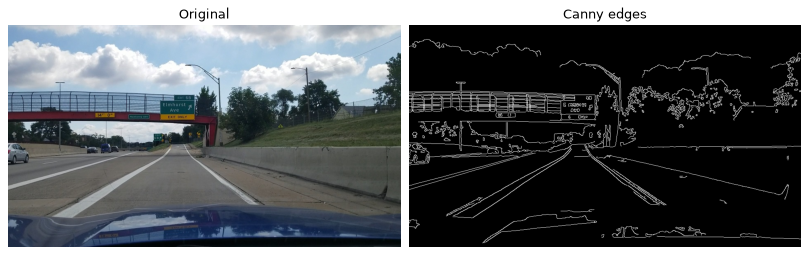

In [4]:
image = load_image(INPUT_PATH)
height, width = image.shape[:2]
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (BLUR_KSIZE, BLUR_KSIZE), 0)
edges = cv2.Canny(blurred, *CANNY_THRESHOLDS)

print(f"Image size (height, width): {height}, {width}")
show_images({"Original": image, "Canny edges": edges}, cols=2)

## 5. Find the vanishing point

The lane segments are searched for in a band of the image above the car's bonnet. The segments are split by slope and fitted, and the two fitted lines meet at the vanishing point.

Search: 6 left and 9 right segments
Vanishing point: x = 415, y = 294


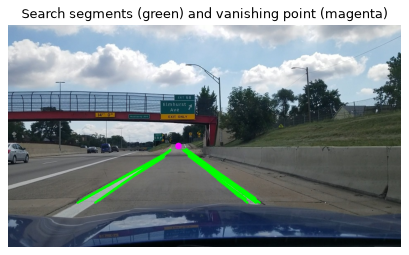

In [5]:
top_row = int(height * SEARCH_TOP_FRACTION)
bottom_row = int(height * SEARCH_BOTTOM_FRACTION)
search_polygon = np.array([[(0, bottom_row), (int(width * 0.31), top_row),
                            (int(width * 0.69), top_row), (width, bottom_row)]], dtype=np.int32)

search_edges = cv2.bitwise_and(edges, roi_mask(gray.shape, search_polygon))
left_search, right_search = find_segments(search_edges)
print(f"Search: {len(left_search)} left and {len(right_search)} right segments")

left_fit = fit_x_of_y(left_search)
right_fit = fit_x_of_y(right_search)
vp = vanishing_point(left_fit, right_fit, height)
print(f"Vanishing point: x = {vp[0]:.0f}, y = {vp[1]:.0f}" if vp else "No valid vanishing point")

view = image.copy()
for x1, y1, x2, y2 in left_search + right_search:
    cv2.line(view, (x1, y1), (x2, y2), (0, 255, 0), 3)
if vp is not None:
    cv2.circle(view, (int(vp[0]), int(vp[1])), 8, (255, 0, 255), thickness=-1)
show_images({"Search segments (green) and vanishing point (magenta)": view})

## 6. Build the region of interest

The region of interest is a trapezoid from the vanishing point down to `ROI_BOTTOM_FRACTION` of the image height. The bottom of the trapezoid is above the car's bonnet, so the bonnet does not enter the mask.

If the vanishing point cannot be found, this notebook stops, because the region of interest has to come from the lanes.

ROI corners (bottom-left, top-left, top-right, bottom-right): [[187, 432], [390, 309], [434, 309], [599, 432]]


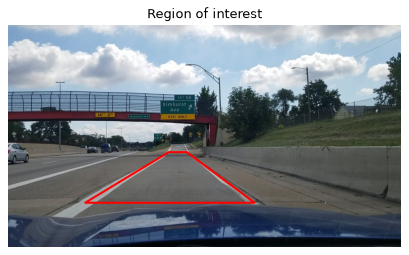

In [6]:
if vp is None:
    raise RuntimeError("No vanishing point found; the lane lines were not detected on both sides.")

roi_bottom = int(height * ROI_BOTTOM_FRACTION)
roi = roi_from_vanishing_point(left_fit, right_fit, vp[1], roi_bottom, width)
print("ROI corners (bottom-left, top-left, top-right, bottom-right):", roi[0].tolist())

show_images({"Region of interest": draw_polygon(image, roi)})

## 7. Detect the lane segments inside the region of interest

The edges are masked with the region of interest, and the probabilistic Hough transform finds the segments inside it. These are the segments that are averaged in the next step.

9 segments inside the region of interest


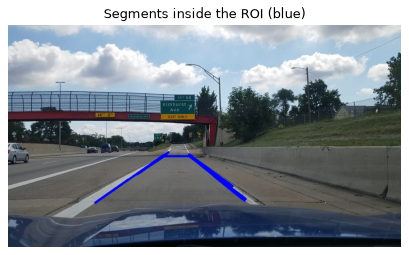

In [7]:
roi_edges = cv2.bitwise_and(edges, roi_mask(gray.shape, roi))
segments = cv2.HoughLinesP(roi_edges, HOUGH_LANE["rho"], HOUGH_LANE["theta"], HOUGH_LANE["threshold"],
                           np.array([]), minLineLength=HOUGH_LANE["min_length"],
                           maxLineGap=HOUGH_LANE["max_gap"])
segments = [] if segments is None else [tuple(int(v) for v in s) for s in segments.reshape(-1, 4)]
print(f"{len(segments)} segments inside the region of interest")

segment_view = image.copy()
for x1, y1, x2, y2 in segments:
    cv2.line(segment_view, (x1, y1), (x2, y2), (255, 0, 0), 4)
show_images({"Segments inside the ROI (blue)": segment_view})

## 8. Average each side and extend it

Each lane is drawn as **one** line, not as many short segments. The segments are split by slope, as in section 5. For each side, one line is fitted through all of its endpoints. The fitted line is then drawn from the bottom of the region of interest to its top, so the lane runs across the whole region.

Averaging makes the result stable. A single short segment that is noisy or partly hidden no longer moves the lane.

left lane: 4 segments averaged
right lane: 4 segments averaged


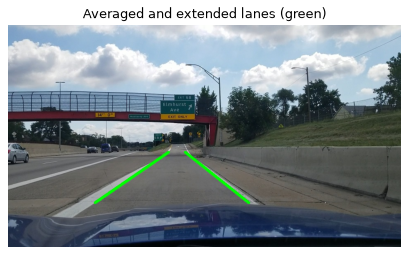

In [8]:
left_segments = []
right_segments = []
for x1, y1, x2, y2 in segments:
    if x2 == x1:
        continue
    slope = (y2 - y1) / (x2 - x1)
    if abs(slope) < MIN_SLOPE:
        continue
    (left_segments if slope < 0 else right_segments).append((x1, y1, x2, y2))

lane_lines = []
for name, group in (("left", left_segments), ("right", right_segments)):
    if not group:
        print(f"No {name} lane segments inside the ROI; this lane is not drawn.")
        continue
    fit = fit_x_of_y(group)
    lane_lines.append(extend_line(fit, vp[1] + TOP_MARGIN, roi_bottom))
    print(f"{name} lane: {len(group)} segments averaged")

averaged_view = image.copy()
for start, end in lane_lines:
    cv2.line(averaged_view, start, end, (0, 255, 0), 6)
show_images({"Averaged and extended lanes (green)": averaged_view})

## 9. Draw the lanes on the photo

The lanes are drawn on a black image with the same size as the photo. The photo and the lane image are then blended with `cv2.addWeighted`, as in the course project.

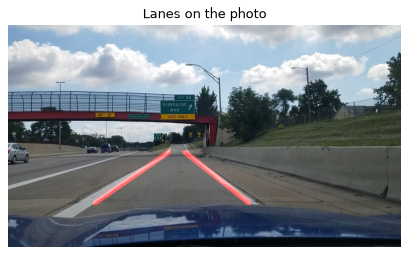

In [9]:
line_image = np.zeros_like(image)
for start, end in lane_lines:
    cv2.line(line_image, start, end, (0, 0, 255), 12)

lanes_on_photo = cv2.addWeighted(image, 1.0, line_image, 1.0, 0)
show_images({"Lanes on the photo": lanes_on_photo})

## 10. Save the results

All results are written to `OUTPUT_DIR`, using the input file name as a prefix.

In [10]:
stem = INPUT_PATH.stem
outputs = {
    "canny": edges,
    "vanishing_point_search": view,
    "roi_outline": draw_polygon(image, roi),
    "segments_in_roi": segment_view,
    "averaged_lanes": averaged_view,
    "lanes_on_photo": lanes_on_photo,
}
for suffix, result in outputs.items():
    save_image(OUTPUT_DIR / f"{stem}_{suffix}.jpg", result)

Saved output/new_test_image_3_canny.jpg
Saved output/new_test_image_3_vanishing_point_search.jpg
Saved output/new_test_image_3_roi_outline.jpg
Saved output/new_test_image_3_segments_in_roi.jpg
Saved output/new_test_image_3_averaged_lanes.jpg
Saved output/new_test_image_3_lanes_on_photo.jpg


## 11. Conclusion

- The **Hough transform** finds straight segments among the edges. Averaging the segments on each side gives one stable line per lane.
- The **vanishing point** sets the region of interest, so the region follows the camera in each image. The bonnet is excluded by a fixed fraction of the image height, which is a camera-specific setting.
- The method is classical and fast, and every step can be checked on the image.

**Limits of this method**
- It assumes that straight lane lines are visible on both sides. Curves, worn markings and other cars can break the fit, and the notebook stops with an error in that case.
- Each image is processed alone. On video, the lanes flicker from frame to frame.

**Current standards beyond this notebook**
- **Curves:** a second-order polynomial fitted in a bird's-eye view replaces the straight line. The perspective transform from the previous notebooks gives that view, and a sliding-window search finds the lane pixels.
- **Video:** the lane fit is smoothed over time, for example with a Kalman filter or by averaging over the last frames, and the region of interest is updated from the previous frame.
- **Learned detectors:** SCNN, LaneNet, UFLD and CLRNet detect lanes with a neural network trained on labelled road images. They are the current standard on benchmarks such as CULane and TuSimple, but they need training data and a GPU for real-time use.